## 데이터 준비 및 전처리

In [1]:
import os
import zipfile
import random
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

if not os.path.isdir('dataset'):
    if not os.path.exists('dataset.zip'):
        from google.colab import files
        files.upload()
    with zipfile.ZipFile('dataset.zip', 'r') as z:
        z.extractall('.')


def prepare_image(image):
    image = image.convert('L')
    mask = ImageOps.invert(image).point(lambda x: 255 if x > 40 else 0)
    bbox = mask.getbbox()
    if bbox is not None:
        image = image.crop(bbox)
        width, height = image.size
        side = int(max(width, height) * 1.5)
        canvas = Image.new('L', (side, side), 255)
        canvas.paste(image, ((side - width) // 2, (side - height) // 2))
        image = canvas
    return image.resize((64, 64), Image.Resampling.LANCZOS)

train_transform = transforms.Compose([
    transforms.Lambda(prepare_image),
    transforms.RandomAffine(degrees=12, translate=(0.10, 0.10), scale=(0.85, 1.15), shear=8, fill=255),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

val_transform = transforms.Compose([
    transforms.Lambda(prepare_image),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.ImageFolder('dataset', transform=train_transform)
val_dataset = datasets.ImageFolder('dataset', transform=val_transform)
class_names = train_dataset.classes
num_classes = len(class_names)

val_writers = [7, 8]
train_indices = [i for i, (path, label) in enumerate(train_dataset.samples)
                 if int(os.path.splitext(os.path.basename(path))[0]) not in val_writers]
val_indices = [i for i, (path, label) in enumerate(train_dataset.samples)
               if int(os.path.splitext(os.path.basename(path))[0]) in val_writers]

train_loader = DataLoader(Subset(train_dataset, train_indices), batch_size=16, shuffle=True)
train_eval_loader = DataLoader(Subset(val_dataset, train_indices), batch_size=16, shuffle=False)
val_loader = DataLoader(Subset(val_dataset, val_indices), batch_size=16, shuffle=False)

print('Classes:', class_names)
print('Train:', len(train_indices), 'Validation:', len(val_indices))

Device: cuda


Saving dataset.zip to dataset.zip
Classes: ['ㄱ', 'ㄴ', 'ㄷ', 'ㄹ', 'ㅁ', 'ㅂ', 'ㅅ', 'ㅇ', 'ㅈ', 'ㅊ', 'ㅋ', 'ㅌ', 'ㅍ', 'ㅎ']
Train: 84 Validation: 28


## 모델 구조 정의

In [2]:
def create_model(name):
    if name == 'MLP':
        return nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(),
        nn.Linear(32 * 4 * 4, 128),
        nn.ReLU(),
        nn.Linear(128, num_classes)
    )

## 정확도 평가 함수

In [3]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

## 모델 학습 및 조건 비교

In [4]:
configs = [
    ('MLP', 0.001),
    ('MLP', 0.0005),
    ('CNN', 0.001),
    ('CNN', 0.0003)
]
num_epochs = 50
criterion = nn.CrossEntropyLoss()
results = []

for model_name, lr in configs:
    model = create_model(model_name).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
    train_acc_history = []
    val_acc_history = []
    train_loss_history = []
    val_loss_history = []
    best_acc = -1
    best_loss = float('inf')
    best_epoch = 1

    for epoch in range(num_epochs):
        model.train()
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        scheduler.step()

        train_loss, train_acc = evaluate(model, train_eval_loader, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        train_loss_history.append(train_loss)
        train_acc_history.append(train_acc)
        val_loss_history.append(val_loss)
        val_acc_history.append(val_acc)

        if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
            best_acc = val_acc
            best_loss = val_loss
            best_epoch = epoch + 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'{model_name} lr={lr} | Epoch {epoch+1}/{num_epochs} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Val Loss: {val_loss:.4f}')

    results.append({
        'name': model_name,
        'lr': lr,
        'best_acc': best_acc,
        'best_loss': best_loss,
        'best_epoch': best_epoch,
        'train_acc_history': train_acc_history,
        'val_acc_history': val_acc_history,
        'train_loss_history': train_loss_history,
        'val_loss_history': val_loss_history
    })

MLP lr=0.001 | Epoch 1/50 | Train Acc: 0.0714 | Val Acc: 0.0714 | Val Loss: 2.6415
MLP lr=0.001 | Epoch 10/50 | Train Acc: 0.4762 | Val Acc: 0.5000 | Val Loss: 1.7639
MLP lr=0.001 | Epoch 20/50 | Train Acc: 0.6905 | Val Acc: 0.6071 | Val Loss: 1.1824
MLP lr=0.001 | Epoch 30/50 | Train Acc: 0.8333 | Val Acc: 0.7143 | Val Loss: 0.9558
MLP lr=0.001 | Epoch 40/50 | Train Acc: 0.8571 | Val Acc: 0.7500 | Val Loss: 0.8763
MLP lr=0.001 | Epoch 50/50 | Train Acc: 0.8690 | Val Acc: 0.6786 | Val Loss: 0.9441
MLP lr=0.0005 | Epoch 1/50 | Train Acc: 0.1786 | Val Acc: 0.1786 | Val Loss: 2.5969
MLP lr=0.0005 | Epoch 10/50 | Train Acc: 0.5476 | Val Acc: 0.6071 | Val Loss: 1.7801
MLP lr=0.0005 | Epoch 20/50 | Train Acc: 0.7262 | Val Acc: 0.6071 | Val Loss: 1.2077
MLP lr=0.0005 | Epoch 30/50 | Train Acc: 0.8690 | Val Acc: 0.7143 | Val Loss: 0.9275
MLP lr=0.0005 | Epoch 40/50 | Train Acc: 0.8571 | Val Acc: 0.6786 | Val Loss: 0.8900
MLP lr=0.0005 | Epoch 50/50 | Train Acc: 0.9167 | Val Acc: 0.7500 | Val L

## 학습 결과 비교 및 시각화

MLP | lr=0.001 | Epoch=33 | Val Acc=0.7857 | Val Loss=0.8393
MLP | lr=0.0005 | Epoch=42 | Val Acc=0.8214 | Val Loss=0.8447
CNN | lr=0.001 | Epoch=44 | Val Acc=0.6429 | Val Loss=1.2286
CNN | lr=0.0003 | Epoch=50 | Val Acc=0.6071 | Val Loss=1.4904
Best: MLP 0.0005 42 0.8214285714285714


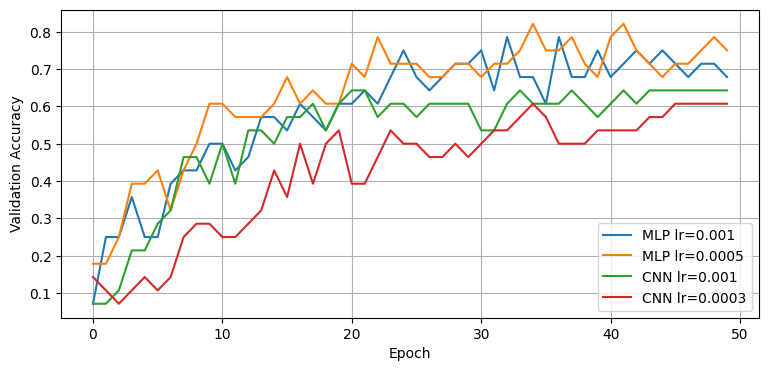

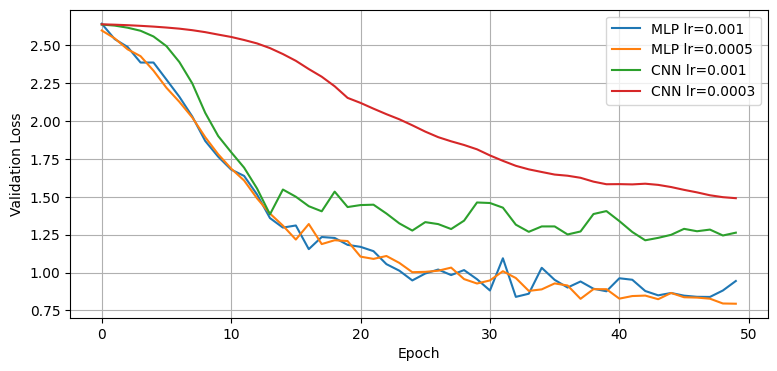

In [5]:
for result in results:
    print(f"{result['name']} | lr={result['lr']} | Epoch={result['best_epoch']} | Val Acc={result['best_acc']:.4f} | Val Loss={result['best_loss']:.4f}")

best_result = sorted(results, key=lambda r: (-r['best_acc'], r['best_loss']))[0]
print('Best:', best_result['name'], best_result['lr'], best_result['best_epoch'], best_result['best_acc'])

plt.figure(figsize=(9, 4))
for result in results:
    plt.plot(result['val_acc_history'], label=f"{result['name']} lr={result['lr']}")
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(9, 4))
for result in results:
    plt.plot(result['val_loss_history'], label=f"{result['name']} lr={result['lr']}")
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid()
plt.show()

## 최적 모델 전체 데이터 학습 및 저장

Final Epoch 1/42 | Train Loss: 2.7598 | Train Acc: 0.0804
Final Epoch 10/42 | Train Loss: 1.8367 | Train Acc: 0.4107
Final Epoch 20/42 | Train Loss: 1.3216 | Train Acc: 0.5714
Final Epoch 30/42 | Train Loss: 1.2992 | Train Acc: 0.5804
Final Epoch 40/42 | Train Loss: 1.2584 | Train Acc: 0.6071
Final Epoch 42/42 | Train Loss: 1.2437 | Train Acc: 0.6250


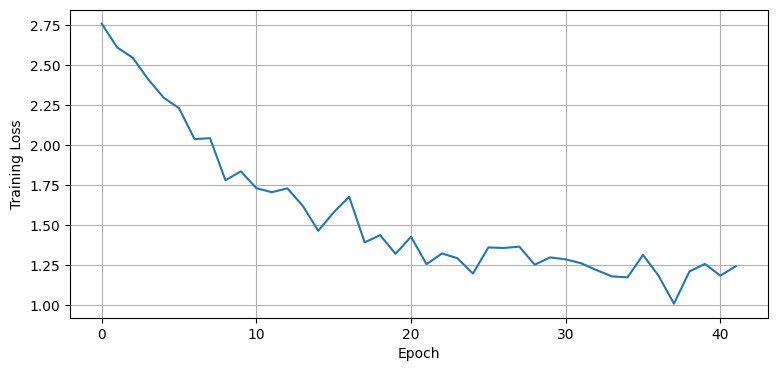

Saved: best_model.pth


In [6]:
full_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
model = create_model(best_result['name']).to(device)
optimizer = optim.Adam(model.parameters(), lr=best_result['lr'])
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
final_epochs = max(30, best_result['best_epoch'])
final_train_loss_history = []
final_train_acc_history = []

for epoch in range(final_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in full_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    scheduler.step()
    final_train_loss_history.append(total_loss / total)
    final_train_acc_history.append(correct / total)
    if (epoch + 1) % 10 == 0 or epoch == 0 or epoch + 1 == final_epochs:
        print(f'Final Epoch {epoch+1}/{final_epochs} | Train Loss: {total_loss/total:.4f} | Train Acc: {correct/total:.4f}')

plt.figure(figsize=(9, 4))
plt.plot(final_train_loss_history)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.grid()
plt.show()

model.eval()
torch.save({
    'model_name': best_result['name'],
    'class_names': class_names,
    'state_dict': model.cpu().state_dict()
}, 'best_model.pth')
print('Saved: best_model.pth')